In [10]:
import wandb
import json
import matplotlib.pyplot as plt
import matplotlib
from matplotlib import rc
rc('text', usetex=True)
import matplotlib.pylab as pylab
params = {'legend.fontsize': '11',
          'figure.figsize': (6,4),
          'axes.labelsize': 18,
          'axes.titlesize': 18,
          'xtick.labelsize': 13,
          'ytick.labelsize': 13}
pylab.rcParams.update(params)
import numpy as np

import scipy.stats as st


In [16]:
data=open('optl_slower_decay.traj','r')
forces=[]
for l in data.readlines():
    s=l.split()
    forces.append(float(s[-2]))
print(min(forces),max(forces))

for i,f in enumerate(forces):
    if f==min(forces):
        print(i)

0.06171 0.6205
23553
23554


Text(0, 0.5, 'Maximum Gradient (eV/$\\mbox{\\AA}$)')

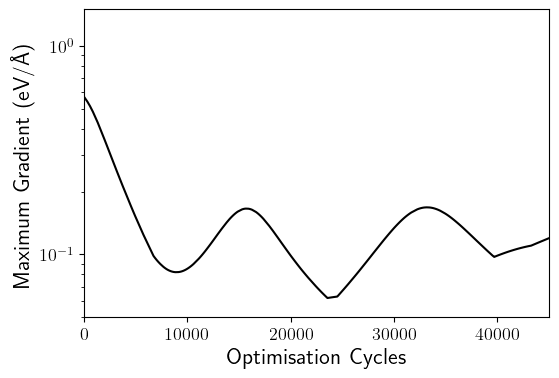

In [15]:
plt.plot(range(len(forces)),forces,'k-')
plt.xlim([0,45000])
plt.ylim([0.05,1.5])
plt.yscale('log')
plt.xlabel('Optimisation Cycles')
plt.ylabel('Maximum Gradient (eV/$\\mbox{\\AA}$)')

0 0.0
3854 4160 0.9264423076923077


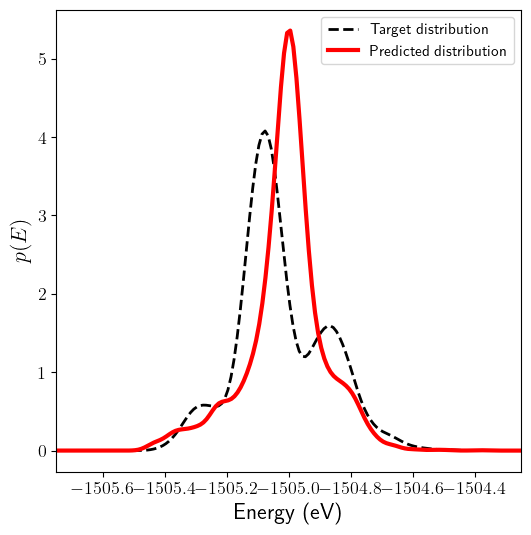

In [65]:
def hist_compare(x, y,title=None):
    import scipy.stats as st
    plt.figure(figsize=(6,6))
    kernel = st.gaussian_kde(x)
    _x=np.arange(min(x)-1,max(x)+1,0.01)
    plt.plot(_x,kernel(_x),'--',c='k',lw=2,label='Target distribution')

    kernel = st.gaussian_kde(y)
    _x=np.arange(min(y)-1,max(y)+1,0.01)
    plt.plot(_x,kernel(_x),'-',c='r',lw=3,label='Predicted distribution')
    plt.xlabel('Energy (eV)')
    plt.ylabel('$p(E)$')
    plt.xlim([-1505.75,-1504.25])
    plt.title(title)
    plt.legend()
    
d=dict(np.load('./LLZO/llzo_12_44/opt_data_cLLZO_12_44_corr_last_frame_large_nn_high_wf.npz',allow_pickle=True))
x=dict(enumerate(d['targets'].flatten()))[0]['E'].flatten()

data=open('./LLZO/llzo_12_44/optimised_energies_LLZO_in_equi_variant_model_new.dat','r')
y=[]
for l in data.readlines():
    y.append(float(l.split()[-1]))

unvalid=len([i for i in y if i>-1502])
print(unvalid,float(unvalid)/float(len(x)))
print(len(y),len(x),float(len(y))/float(len(x)))
hist_compare(x, y)

19333
19326


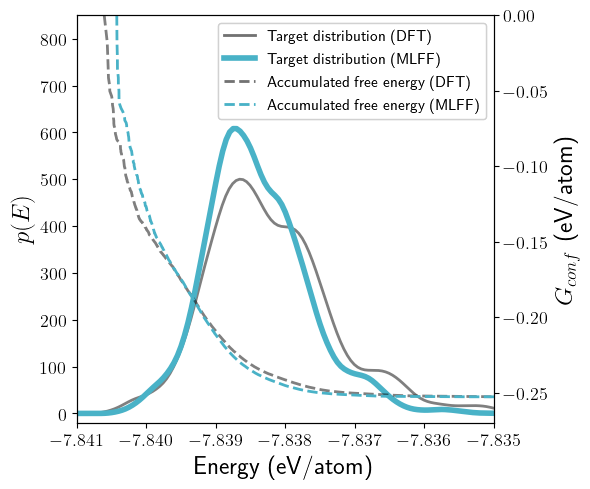

In [7]:
import scipy.stats as st
import math


kT=8.6173303e-5*300
Natoms=56+96+24+16

d=dict(np.load('./LLZO/llzo_11_45/opt_data_cLLZO_11_45_opt_partial_set_last_frame.npz',allow_pickle=True))
x=list(sorted(d['E']))
x=[i/Natoms for i in x] 
min_e=min(x)
print(len(x))
kernel = st.gaussian_kde(x)
_x=np.arange(min(x)-0.002,max(x)+0.002,0.00005)
fig, ax1 = plt.subplots(figsize=(6,5))
line1, = ax1.plot(_x,kernel(_x),'-',c='k',lw=2,alpha=0.5,label='Target distribution (DFT)')
ax1.set_xlabel('Energy (eV/atom)')
ax1.set_ylabel('$p(E)$')
ax1.set_ylim([-20,850])


free_energies=[]

for i in range(1,len(x)):
    Z=sum([math.exp(-(j-min_e)/kT) for j in x[:i]])
    free_energies.append(-kT*math.log(Z))
ax2 = ax1.twinx() 
line2, = ax2.plot(x[1:],free_energies,'--',c='k',lw=2,alpha=0.5,label='Accumulated free energy (DFT)')
ax2.set_ylabel('$G_{conf}$ (eV/atom)')



data=open('./LLZO/llzo_11_45/optimised_energies_LLZO_11_45_in_equi_variant_model_new.dat','r')
y=[]
for l in data.readlines():
    y.append(float(l.split()[-1]))
y=list(sorted(y))
y=[i/Natoms for i in y]
min_e=min(y)
print(len(y))
kernel = st.gaussian_kde(y)
_y=np.arange(min(y)-0.002,max(y)+0.002,0.00005)
line3, = ax1.plot(_y,kernel(_y),'-',c='#49B2C7',lw=4,label='Target distribution (MLFF)')

free_energies=[]
for i in range(1,len(y)):
    Z=sum([math.exp(-(j-min_e)/kT) for j in y[:i]])
    free_energies.append(-kT*math.log(Z))
line4, = ax2.plot(y[1:],free_energies,'--',c='#49B2C7',lw=2,label='Accumulated free energy (MLFF)')


"""
data=open('./LLZO/llzo_11_45/optimised_energies_LLZO_11_45_in_equi_variant_model_fullset.dat','r')
y=[]
for l in data.readlines():
    y.append(float(l.split()[-1]))
y=list(sorted(y))
y=[i/Natoms for i in y]

print(len(y))
kernel = st.gaussian_kde(y)
_y=np.arange(min(y)-0.002,max(y)+0.002,0.00005)
line5, = ax1.plot(_y,kernel(_y),'-',c='b',lw=2,label='Distribution full set (so3krates)')

free_energies=[]
for i in range(1,len(y)):
    Z=sum([math.exp(-(j)/kT) for j in y[:i]])
    free_energies.append(-kT*math.log(Z))
line6, = ax2.plot(y[1:],free_energies,'--',c='b',lw=1,label='Accumulated free energy full set (so3krates)')

"""
legend1 = plt.legend(handles=[line1,line3,line2,line4], loc='upper right')
#legend2 = plt.legend(handles=[line2,line4], loc='upper right')
plt.gca().add_artist(legend1)
#plt.gca().add_artist(legend2)


ax2.set_ylim([-0.27,0])
ax1.set_xlim([-7.841,-7.835])


plt.tight_layout()
plt.savefig('11_45_opt_set_energy_distribution.pdf')

plt.show()


4160
von DFT:
Z:	3838.3453925132835
<E>:	-7.838696778788569
S_conf:	0.0007111707476411815
-TS_conf:	-0.21335122429235445


/var/folders/q5/dn8rdk613pj4bx_9jv6fyz1h0000gp/T/ipykernel_7028/365913223.py:67: DeprecationWarning: Pickled array contains an aval with a named_shape attribute. This is deprecated and the code path supporting such avals will be removed. Please re-pickle the array.
  data=pickle.load(open('LLZO/llzo_12_44/sampler_lbfgs/sampling_run_'+str(i)+'.bp','rb'))


-0.21354206867172404
von MLFF:
<E>:	-7.838639
S_conf:	0.0007118068955724135
-TS_conf:	-0.21354206867172404


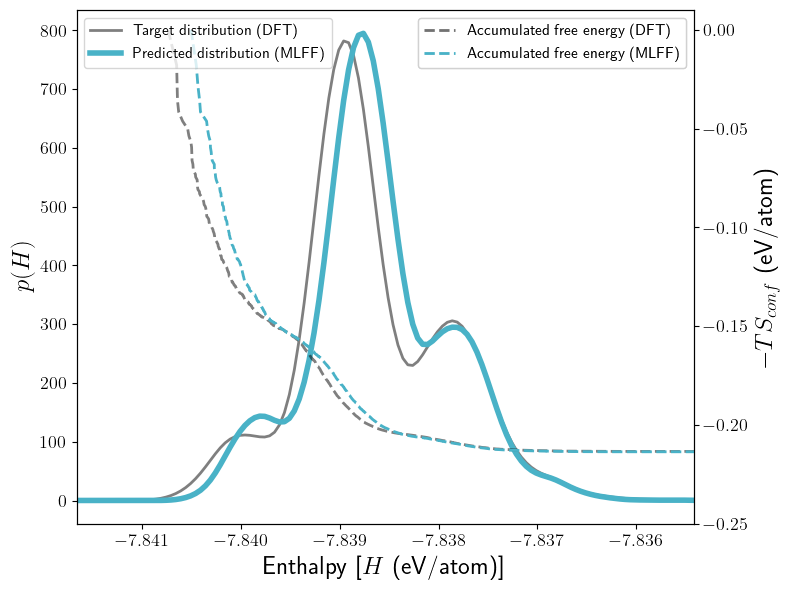

In [20]:
import math

Natoms=56+96+24+16
kT=8.6173303e-5*300
k=8.6173303e-5

E_Li=-3.689
E_O=-4.973
E_Zr=-10.261
E_La=-4.686
E_ele_tot=E_Li*56+E_O*96+E_Zr*16+E_La*24

#================================================================================
# target data from DFT calculations, only want the last frame that contains
# the total energies of optimised structures of c-LLZO
#================================================================================

d=dict(np.load('./LLZO/llzo_12_44/opt_data_cLLZO_12_44_corr_last_frame_large_nn_high_wf.npz',allow_pickle=True))
x=dict(enumerate(d['targets'].flatten()))[0]['E'].flatten()
x=list(sorted(x))
x=[_x/Natoms for  _x in x]

print(len(x))
kernel = st.gaussian_kde(x)
_x_dft=np.arange(min(x)-0.002,max(x),0.00005)
fig, ax1 = plt.subplots(figsize=(8,6))
line1, = ax1.plot(_x_dft,kernel(_x_dft),'-',c='k',lw=2,alpha=0.5,label='Target distribution (DFT)')
ax1.set_xlabel('Enthalpy [$H$ (eV/atom)]')
ax1.set_ylabel('$p(H)$')


free_energies=[]
s_conf=0

xmin=min(x)
xx=[i-xmin for i in x] #partition function should be measured with respect to the global minimum in the ensemble

for i in range(1,len(xx)):
    Z=sum([math.exp(-1.0*j/kT) for j in xx[:i]])
    free_energies.append(-kT*math.log(Z))
    s_conf=k*math.log(Z)    
ax2 = ax1.twinx() 
line2, = ax2.plot(x[1:],free_energies,'--',c='k',lw=2,alpha=0.5,label='Accumulated free energy (DFT)')

E_exp=sum([j*math.exp(-(j-xmin)/kT) for j in x])/sum([math.exp(-(j-xmin)/kT) for j in x])
print("von DFT:")
print("Z:\t"+str(Z))
print("<E>:\t"+str(E_exp))
print("S_conf:\t"+str(s_conf))
print("-TS_conf:\t"+str(free_energies[-1]))


ax2.set_ylabel('$-TS_{conf}$ (eV/atom)')

#d=dict(np.load('./LLZO/llzo_12_44/opt_data_cLLZO_12_44_corr_last_frame_large_nn_high_wf.npz',allow_pickle=True))
#x=dict(enumerate(d['targets'].flatten()))[0]['E'].flatten()

#================================================================================
# predicted energies from so3krates
#================================================================================
import glob,pickle

all_data=glob.glob('LLZO/llzo_12_44/sampler_lbfgs/sampling_run_*.bp')

local_minima=[]
for i in range(len(all_data)):
    data=pickle.load(open('LLZO/llzo_12_44/sampler_lbfgs/sampling_run_'+str(i)+'.bp','rb'))
    for j in range(len(data)):
        try:
            if data[j]['local_minimum_energy'] is not None:
                local_minima.append(data[j]['local_minimum_energy']/Natoms)
        except:
            pass

kernel = st.gaussian_kde(local_minima)
x=list(sorted(local_minima))
line3, = ax1.plot(_x_dft,kernel(_x_dft),'-',c='#49B2C7',lw=4,label='Predicted distribution (MLFF)')

free_energies=[]
s_conf=0

xmin=min(x)
xx=[i-xmin for i in x] #partition function should be measured with respect to the global minimum in the ensemble

for i in range(1,len(xx)):
    _xx=np.array(xx[:i])
    _zz=np.exp(-1.0*_xx/(kT))
    Z=np.sum(_zz)
    free_energies.append(-kT*math.log(Z))
    s_conf=k*math.log(Z)    

line4, = ax2.plot(x[1:],free_energies,'--',c='#49B2C7',lw=2,label='Accumulated free energy (MLFF)')
print(free_energies[-1])

E_exp=sum([j*math.exp(-(j-xmin)/kT) for j in x])/sum([math.exp(-(j-xmin)/kT) for j in x])
print("von MLFF:")
print("<E>:\t"+str(E_exp))
print("S_conf:\t"+str(s_conf))
print("-TS_conf:\t"+str(free_energies[-1]))
      
legend1 = plt.legend(handles=[line1,line3], loc='upper left')
legend2 = plt.legend(handles=[line2,line4], loc='upper right')
plt.gca().add_artist(legend1)
plt.gca().add_artist(legend2)

ax2.set_ylim([-0.25,0.01])

plt.xlim([-1505.6/Natoms,-1504.4/Natoms])
#plt.legend(fontsize=12)
plt.tight_layout()
plt.savefig('12_44_opt_set_energy_distribution.pdf')
plt.show()

In [9]:
import math
E=y
kT=8.6173303e-5*300
Natoms=56+96+24+16
Z=sum([math.exp(-(i/Natoms)/kT) for i in E])
P=[(1.0/Z)*math.exp(-(i/Natoms)/kT) for i in E]
E_exp=sum([P[i]*E[i] for i in range(len(E))])

print("Averaged energy is :"+str(E_exp/Natoms))
print("Configurational free energy is:"+str(-kT*math.log(Z)))

Averaged energy is :-7.83861293843389
Configurational free energy is:-8.052061149519483


In [22]:
(-1505.0298+1504.8791)/Natoms

-0.0007848958333328918